In [23]:
import pandas as pd
import matplotlib.pyplot as plt
from linearmodels.panel import PanelOLS, compare
import numpy as np

In [35]:
INDEX_COLS = ['alpha', 'beta', 'gamma']
QUARTER_PANEL_PATH = '../data/checkpoints/panel_q.csv'
BIANNUAL_PANEL_PATH = '../data/checkpoints/panel_h.csv'
FULL_PANEL_PATH = '../data/checkpoints/panel_q_full.csv'
FILTERS_PATH = '../data/checkpoints/passing_occs.json'

GRAPHS_PATH = '../temp/graphics/graphs/'
TABLES_PATH = '../temp/graphics/tables/'
EVENT_STUDY_FOLDER = 'event_studies/'


REFERENCE_QUINTILE = 1

quintiles = [1,2,3,4,5]
quintiles.remove(REFERENCE_QUINTILE)

DV_COL = 'Y_SHARE'
DV_NAME = 'Entry-Level Workers Share'

In [36]:
panel_q = pd.read_csv(QUARTER_PANEL_PATH)
panel_h = pd.read_csv(BIANNUAL_PANEL_PATH)
panel_q_full = pd.read_csv(FULL_PANEL_PATH)

filters = pd.read_json(FILTERS_PATH)

In [40]:
def event_study(panel, window, dv_col, dv_name, quintile, index):
    df_event = panel.set_index(['OCC', window], drop=False)

    # Filter out unselected quintiles
    df_event = df_event[df_event[f'{index}_quintile'].isin([REFERENCE_QUINTILE, quintile])]

    # Get Quarter Dummies 
    df_event = pd.get_dummies(df_event, columns=[window], drop_first=False, dtype=int)

    # Drop the reference period and create list of dummies
    df_event = df_event.drop(columns=[f"{window}_-1"])
    quarter_dummies = [c for c in df_event.columns if c.startswith(f"{window}_")]
    # Create interaction terms and event study formula
    interaction_terms = ' + '.join([f'{index}_quintile_{quintile}:Q("{d}")' for d in quarter_dummies])
    formula = f"{dv_col} ~ {interaction_terms} + EntityEffects + TimeEffects"
    print(f"EVENT STUDY FORMULA: {formula} {'-'*30}")

    # Event study in PANELOLS
    event_study_mod = PanelOLS.from_formula(formula, data=df_event, weights=df_event['N'])
    event_study_res = event_study_mod.fit(cov_type='clustered', cluster_entity=True)
    print(event_study_res.summary)

    # Save output to tex file
    # dv_slug = DV_NAME.replace(' ', '_')
    #with open(f"{TABLES_PATH}{EVENT_STUDY_FOLDER}{dv_slug}_Quintile{quintile}_reg.tex", "w") as f:
    #     f.write(event_study_res.summary.as_latex())

    df_res = pd.DataFrame({
        'coef': event_study_res.params,
        'lower': event_study_res.conf_int()['lower'],
        'upper': event_study_res.conf_int()['upper']
    })

    # Reorganize to reinsert omitted variable
    df_res['quarter'] = df_res['quarter'] = (
        df_res.index
        .str.extract(rf"{window}_(-?\d+)", expand=False)
        .astype(int)
    )
    baseline = pd.DataFrame({'coef': 0.0, 'lower': 0.0, 'upper': 0.0, 'quarter': -1}, index=[-1])
    df_res = pd.concat([df_res, baseline]).sort_values('quarter').reset_index(drop=True)

    # Create graph
    fig, ax = plt.subplots(figsize=(10, 5), dpi=300)

    yerr_lower = df_res['coef'] - df_res['lower']
    yerr_upper = df_res['upper'] - df_res['coef']

    ax.errorbar(
        x=df_res['quarter'],
        y=df_res['coef'],
        yerr=np.asanyarray([yerr_lower, yerr_upper]),
        fmt='o',
        color='black',
        ecolor='gray',
        capsize=3,             
        linestyle='None',
        label='Point estimate (95% CI)'
    )

    ax.plot(df_res['quarter'], df_res['coef'], color='navy', alpha=0.5)

    ax.grid(True, linestyle=':', alpha=0.6)

    ax.axvline(x=0, color='r', linestyle='--', linewidth=2, alpha=0.3, label="t=0 treatment")
    ax.axhline(y=0, color='black', linestyle='--', linewidth=2)
    ax.set_xticks(sorted(df_res['quarter'].unique()))

    ax.set_xlabel('Quarters from treatment (t=0)', labelpad=12)
    ax.set_ylabel('Coefficient estimate', labelpad=12)
    ax.set_title(f'Event Study: {dv_name} around treatment, Lowest Quintile vs Quintile {quintile}', pad=12)

    y_max = max(df_res['upper'].abs().max(), df_res['lower'].abs().max())
    margin = y_max * 0.1  # 10% padding, adjust to taste
    ax.set_ylim(-(y_max + margin), y_max + margin)
    if(window == 'QUARTER'):
        ax.axvspan(10, 12, color='r', alpha = 0.2, label= "Omitted due to\nOctober 2025 CPS")

    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False, loc='center left', bbox_to_anchor=(1.02, 0.5))

    plt.tight_layout()

    # Save graph
    # fig.savefig(f"{GRAPHS_PATH}{EVENT_STUDY_FOLDER}{dv_slug}_Quintile{quintile}_EventStudy.png", dpi=300, bbox_inches='tight')

EVENT STUDY FORMULA: Y_SHARE ~ beta_quintile_5:Q("QUARTER_-8") + beta_quintile_5:Q("QUARTER_-7") + beta_quintile_5:Q("QUARTER_-6") + beta_quintile_5:Q("QUARTER_-5") + beta_quintile_5:Q("QUARTER_-4") + beta_quintile_5:Q("QUARTER_-3") + beta_quintile_5:Q("QUARTER_-2") + beta_quintile_5:Q("QUARTER_0") + beta_quintile_5:Q("QUARTER_1") + beta_quintile_5:Q("QUARTER_2") + beta_quintile_5:Q("QUARTER_3") + beta_quintile_5:Q("QUARTER_4") + beta_quintile_5:Q("QUARTER_5") + beta_quintile_5:Q("QUARTER_6") + beta_quintile_5:Q("QUARTER_7") + beta_quintile_5:Q("QUARTER_8") + beta_quintile_5:Q("QUARTER_9") + beta_quintile_5:Q("QUARTER_10") + beta_quintile_5:Q("QUARTER_12") + beta_quintile_5:Q("QUARTER_13") + beta_quintile_5:Q("QUARTER_14") + EntityEffects + TimeEffects ------------------------------
                          PanelOLS Estimation Summary                           
Dep. Variable:                Y_SHARE   R-squared:                        0.0200
Estimator:                   PanelOLS   R-sq

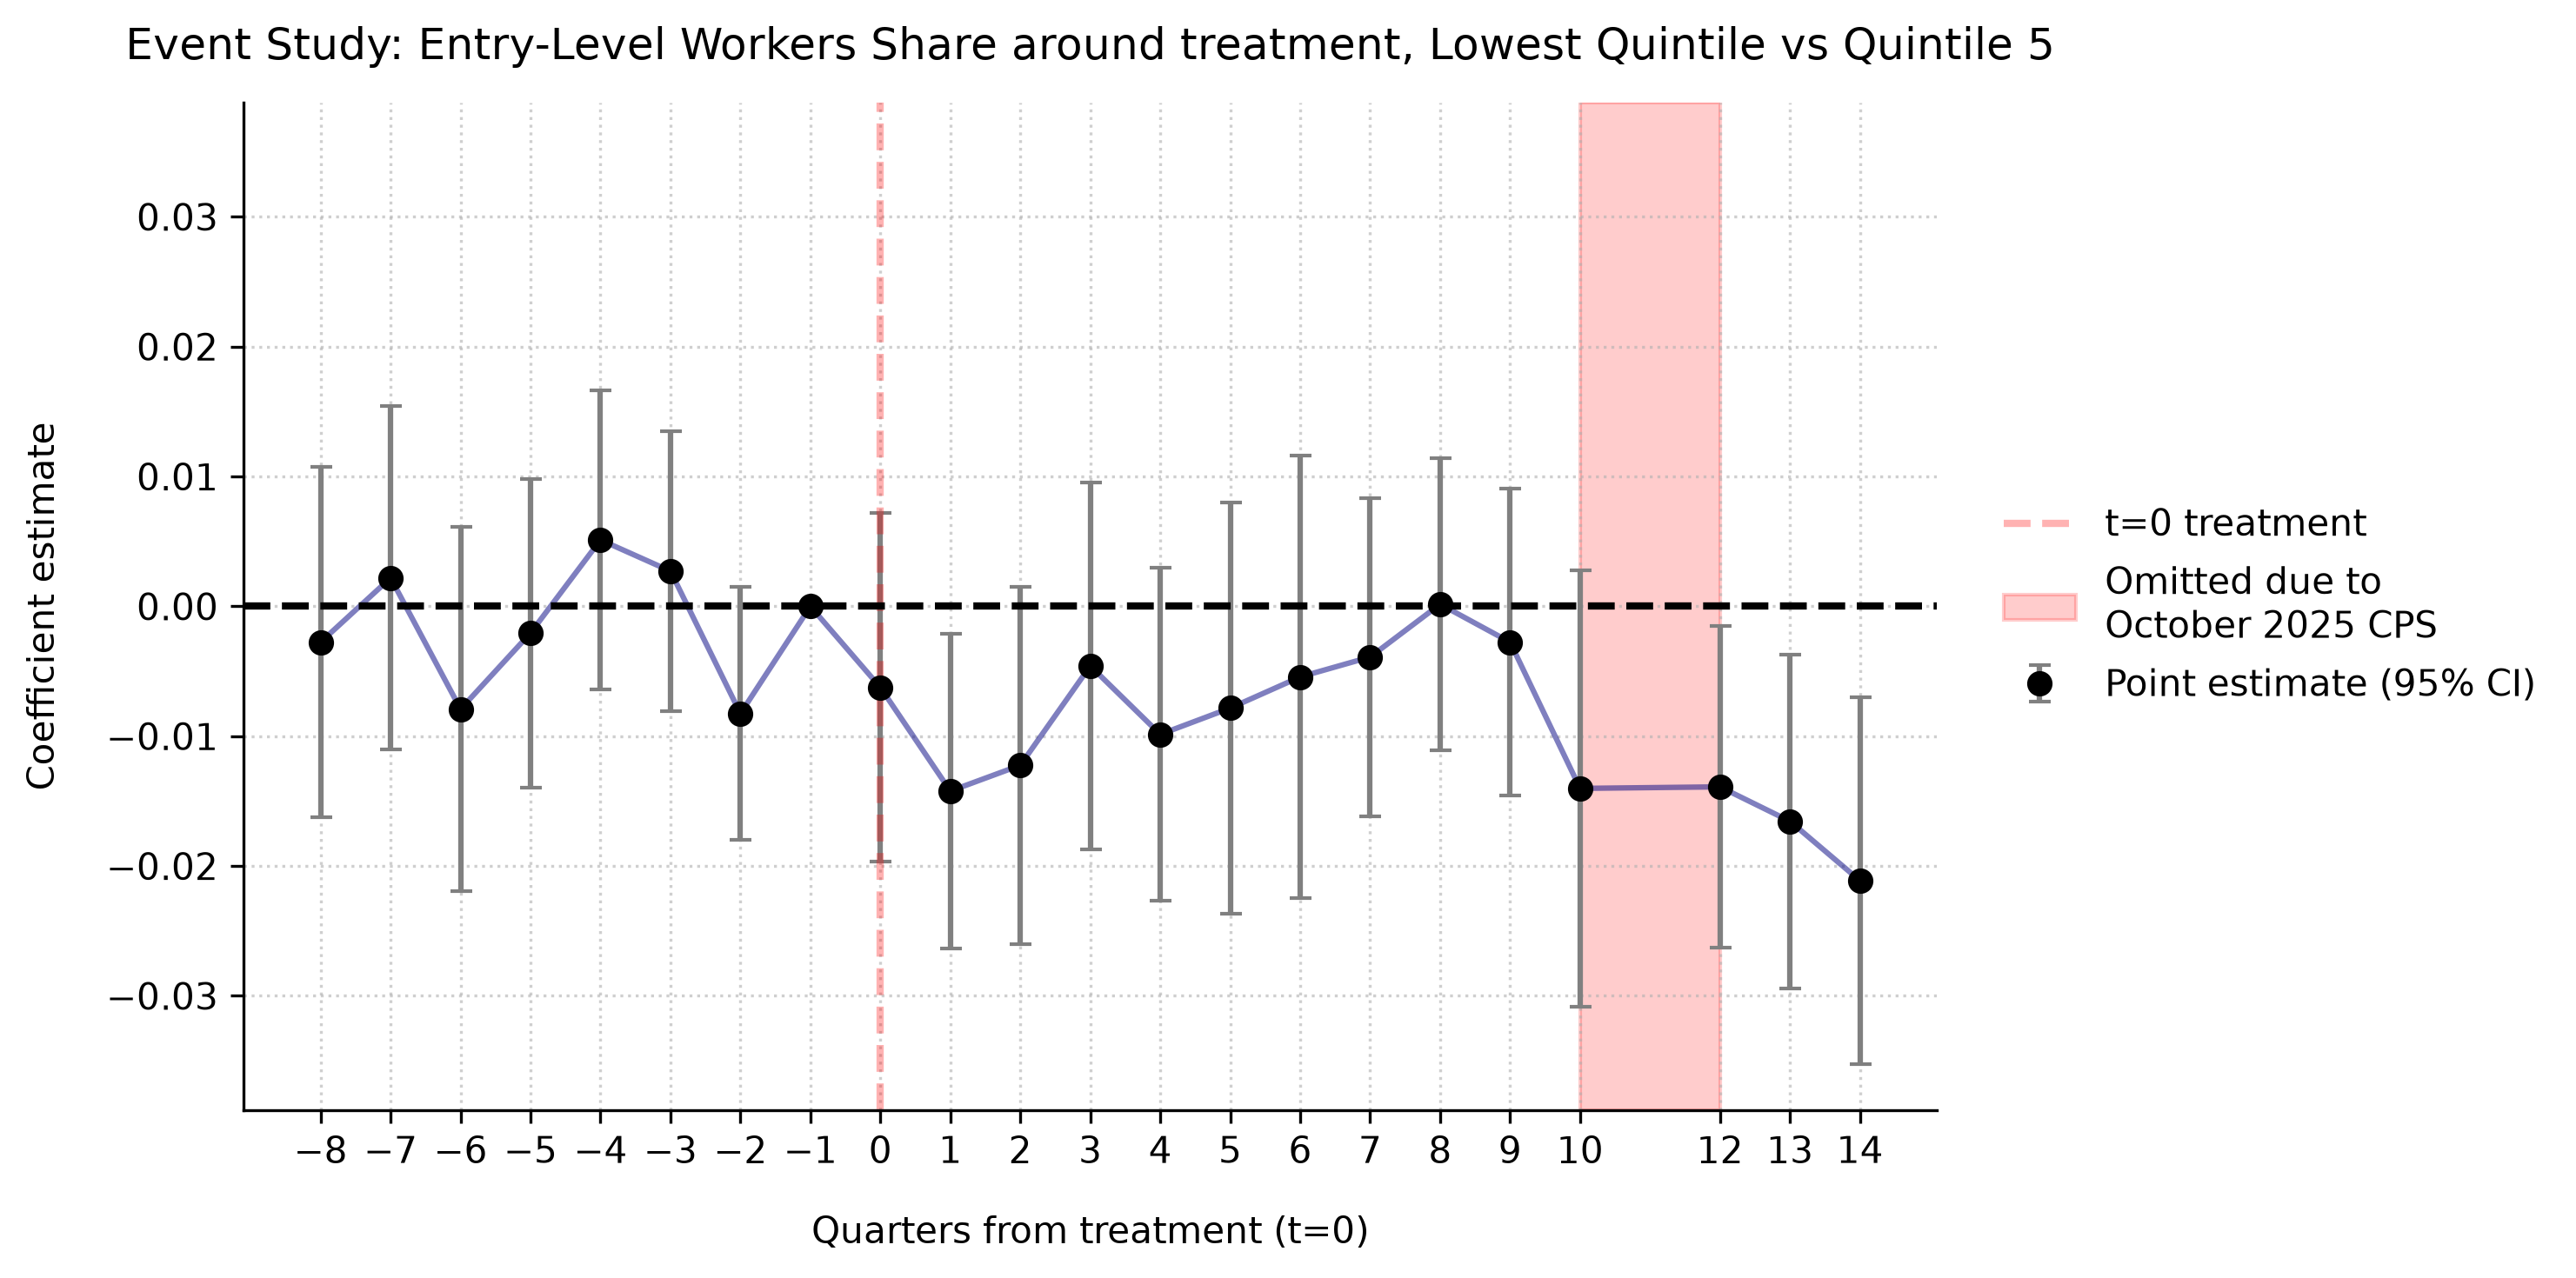

In [41]:
event_study(panel_q, 'QUARTER', DV_COL, DV_NAME, 5, 'beta')

EVENT STUDY FORMULA: Y_SHARE ~ alpha_quintile_5:Q("QUARTER_-8") + alpha_quintile_5:Q("QUARTER_-7") + alpha_quintile_5:Q("QUARTER_-6") + alpha_quintile_5:Q("QUARTER_-5") + alpha_quintile_5:Q("QUARTER_-4") + alpha_quintile_5:Q("QUARTER_-3") + alpha_quintile_5:Q("QUARTER_-2") + alpha_quintile_5:Q("QUARTER_0") + alpha_quintile_5:Q("QUARTER_1") + alpha_quintile_5:Q("QUARTER_2") + alpha_quintile_5:Q("QUARTER_3") + alpha_quintile_5:Q("QUARTER_4") + alpha_quintile_5:Q("QUARTER_5") + alpha_quintile_5:Q("QUARTER_6") + alpha_quintile_5:Q("QUARTER_7") + alpha_quintile_5:Q("QUARTER_8") + alpha_quintile_5:Q("QUARTER_9") + alpha_quintile_5:Q("QUARTER_10") + alpha_quintile_5:Q("QUARTER_12") + alpha_quintile_5:Q("QUARTER_13") + alpha_quintile_5:Q("QUARTER_14") + EntityEffects + TimeEffects ------------------------------
                          PanelOLS Estimation Summary                           
Dep. Variable:                Y_SHARE   R-squared:                        0.0245
Estimator:             

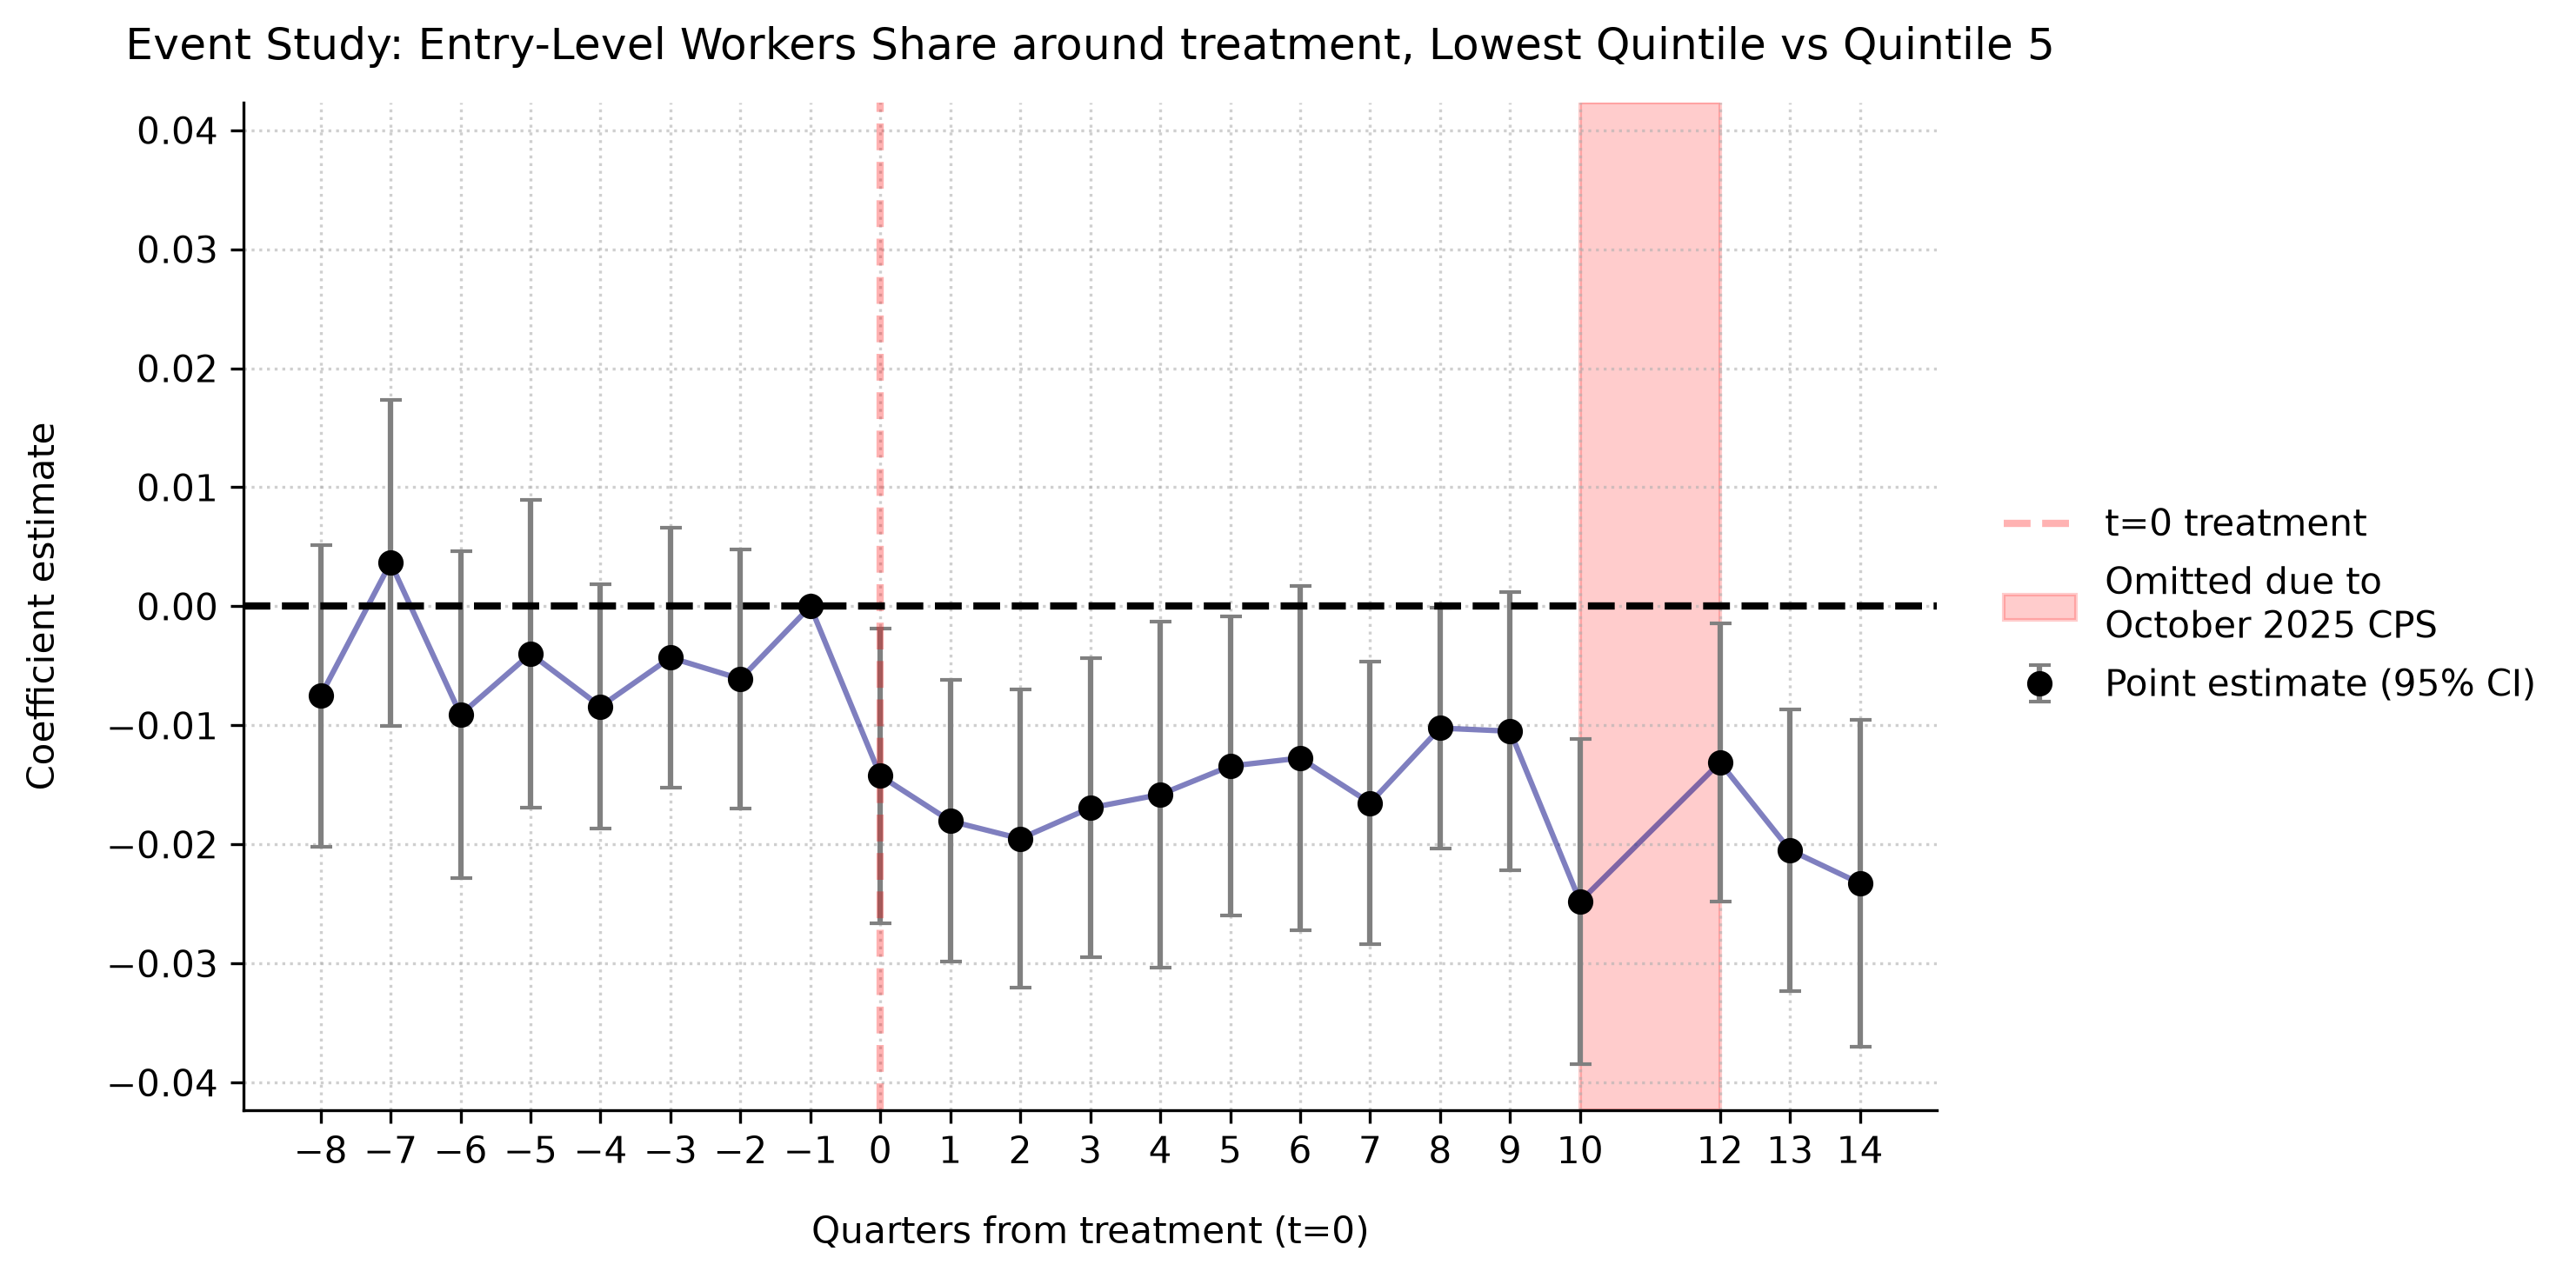

In [43]:
event_study(panel_q, 'QUARTER', DV_COL, DV_NAME, 5, 'alpha')

EVENT STUDY FORMULA: Y_SHARE ~ beta_quintile_5:Q("HALF_YEAR_-4") + beta_quintile_5:Q("HALF_YEAR_-3") + beta_quintile_5:Q("HALF_YEAR_-2") + beta_quintile_5:Q("HALF_YEAR_0") + beta_quintile_5:Q("HALF_YEAR_1") + beta_quintile_5:Q("HALF_YEAR_2") + beta_quintile_5:Q("HALF_YEAR_3") + beta_quintile_5:Q("HALF_YEAR_4") + beta_quintile_5:Q("HALF_YEAR_5") + beta_quintile_5:Q("HALF_YEAR_6") + EntityEffects + TimeEffects ------------------------------
                          PanelOLS Estimation Summary                           
Dep. Variable:                Y_SHARE   R-squared:                        0.0160
Estimator:                   PanelOLS   R-squared (Between):             -0.0066
No. Observations:                1375   R-squared (Within):              -0.0084
Date:                Wed, Oct 07 2026   R-squared (Overall):             -0.0066
Time:                        12:05:03   Log-likelihood                    3385.2
Cov. Estimator:             Clustered                                  

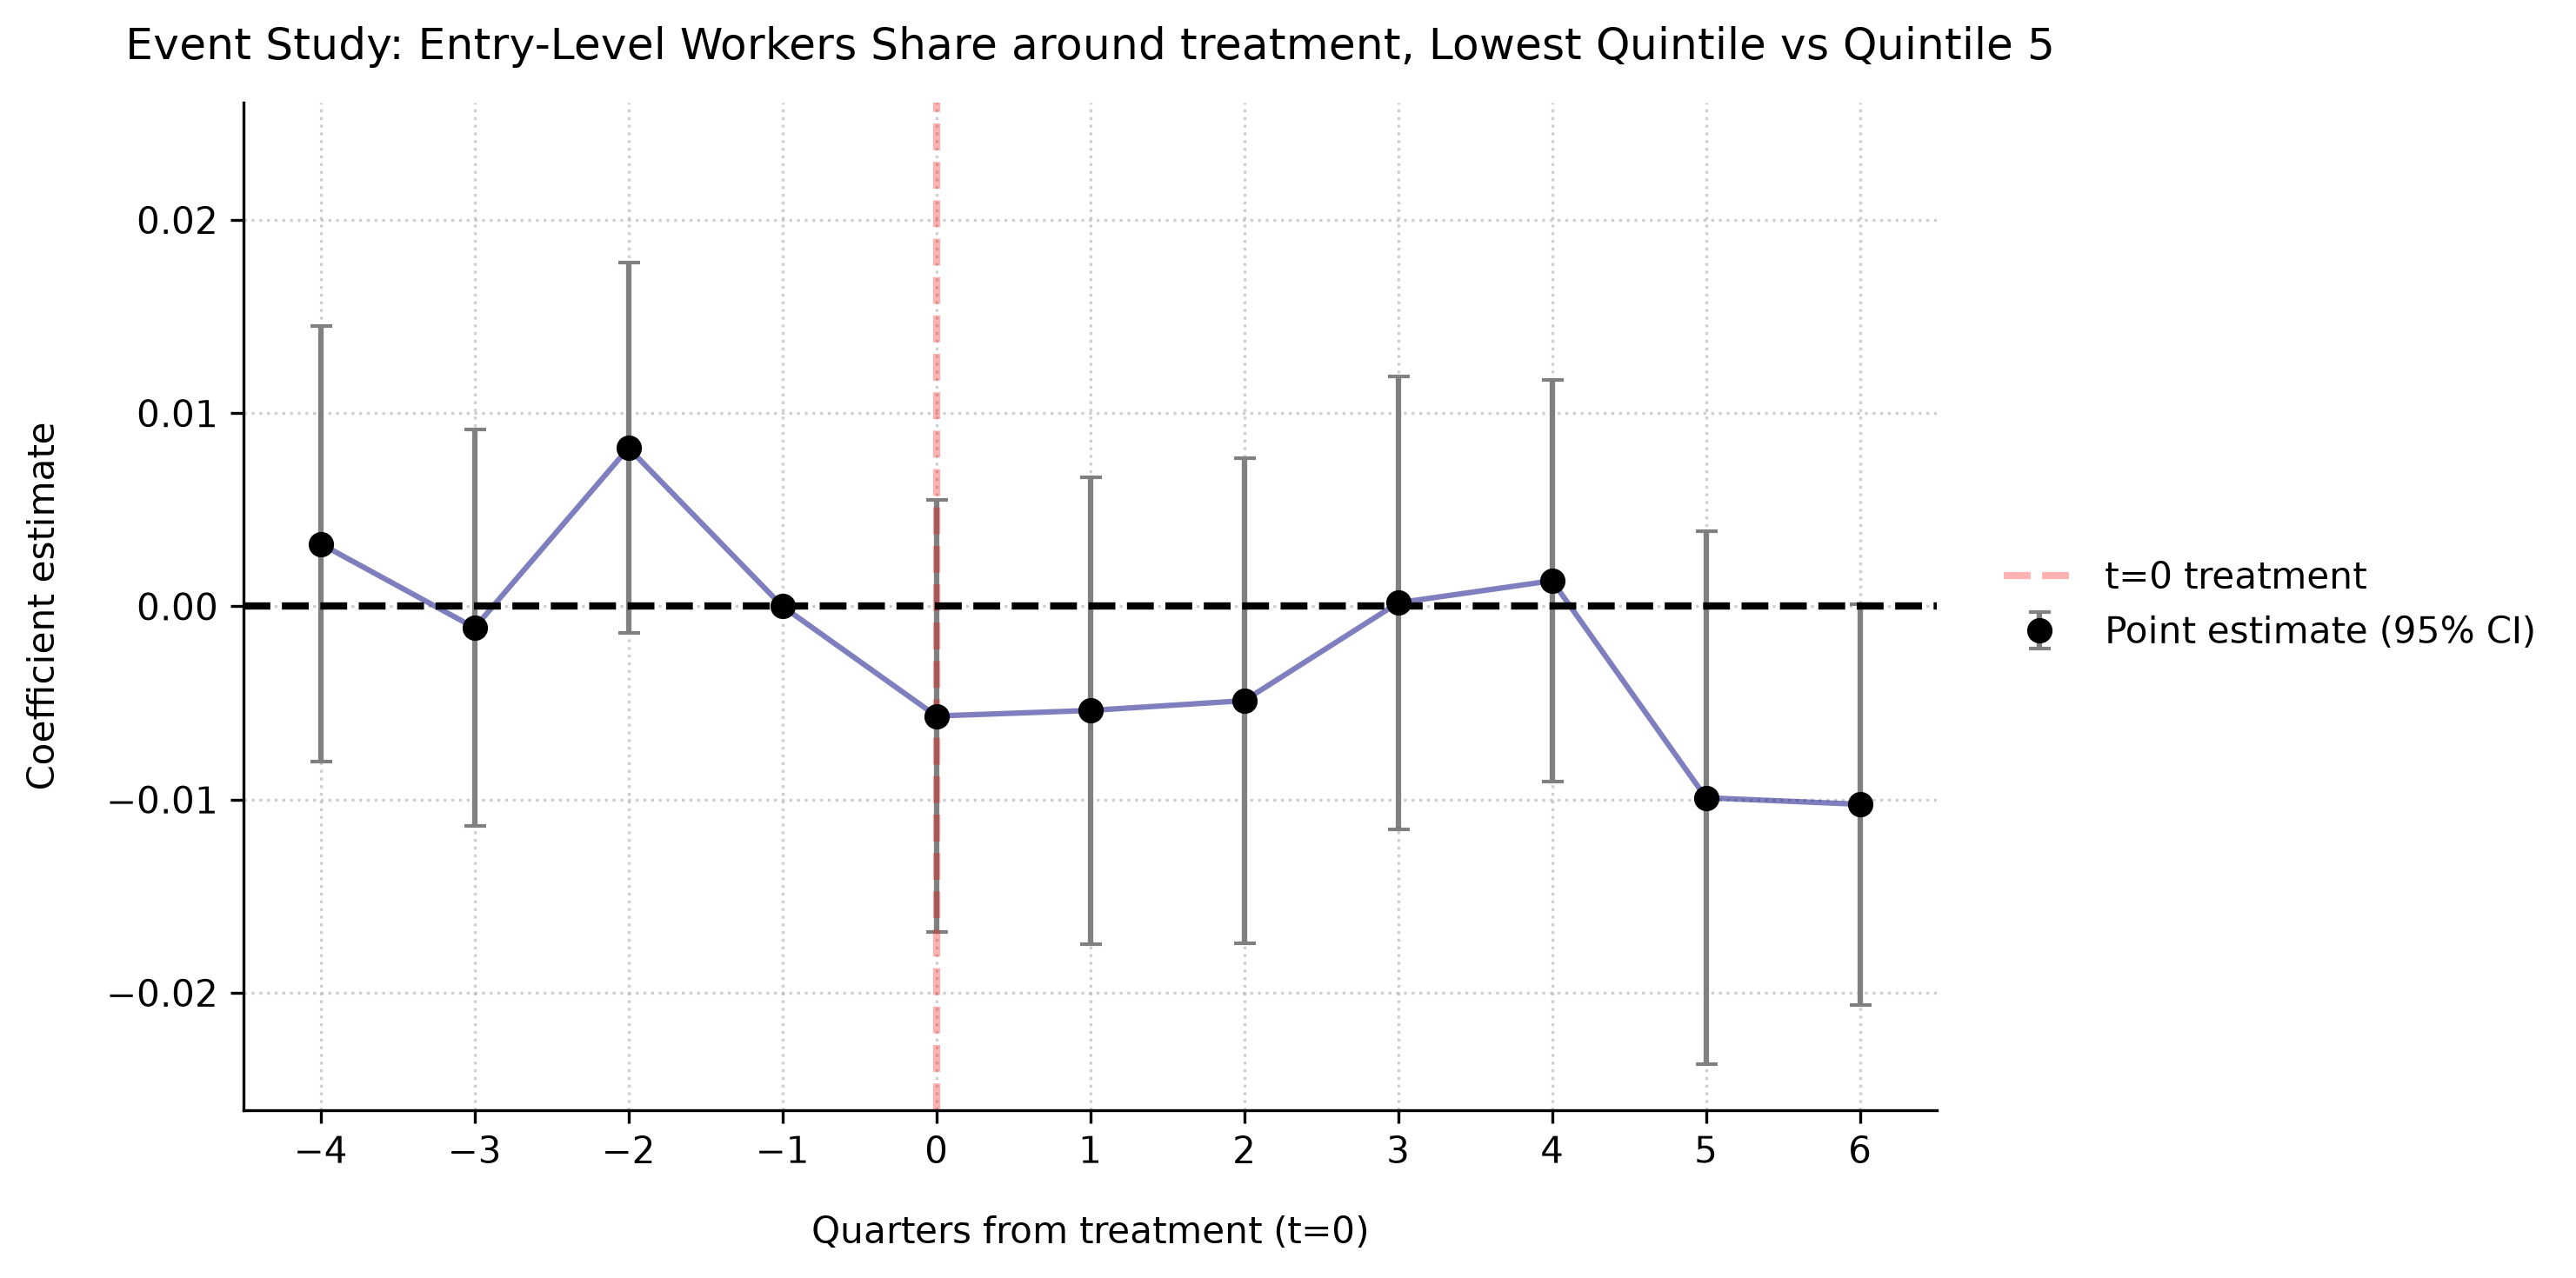

In [33]:
event_study(panel_h, 'HALF_YEAR', DV_COL, DV_NAME, 5)

EVENT STUDY FORMULA: Y_SHARE ~ alpha_quintile_5:Q("QUARTER_-8") + alpha_quintile_5:Q("QUARTER_-7") + alpha_quintile_5:Q("QUARTER_-6") + alpha_quintile_5:Q("QUARTER_-5") + alpha_quintile_5:Q("QUARTER_-4") + alpha_quintile_5:Q("QUARTER_-3") + alpha_quintile_5:Q("QUARTER_-2") + alpha_quintile_5:Q("QUARTER_0") + alpha_quintile_5:Q("QUARTER_1") + alpha_quintile_5:Q("QUARTER_2") + alpha_quintile_5:Q("QUARTER_3") + alpha_quintile_5:Q("QUARTER_4") + alpha_quintile_5:Q("QUARTER_5") + alpha_quintile_5:Q("QUARTER_6") + alpha_quintile_5:Q("QUARTER_7") + alpha_quintile_5:Q("QUARTER_8") + alpha_quintile_5:Q("QUARTER_9") + alpha_quintile_5:Q("QUARTER_10") + alpha_quintile_5:Q("QUARTER_12") + alpha_quintile_5:Q("QUARTER_13") + alpha_quintile_5:Q("QUARTER_14") + EntityEffects + TimeEffects ------------------------------
                          PanelOLS Estimation Summary                           
Dep. Variable:                Y_SHARE   R-squared:                        0.0106
Estimator:             

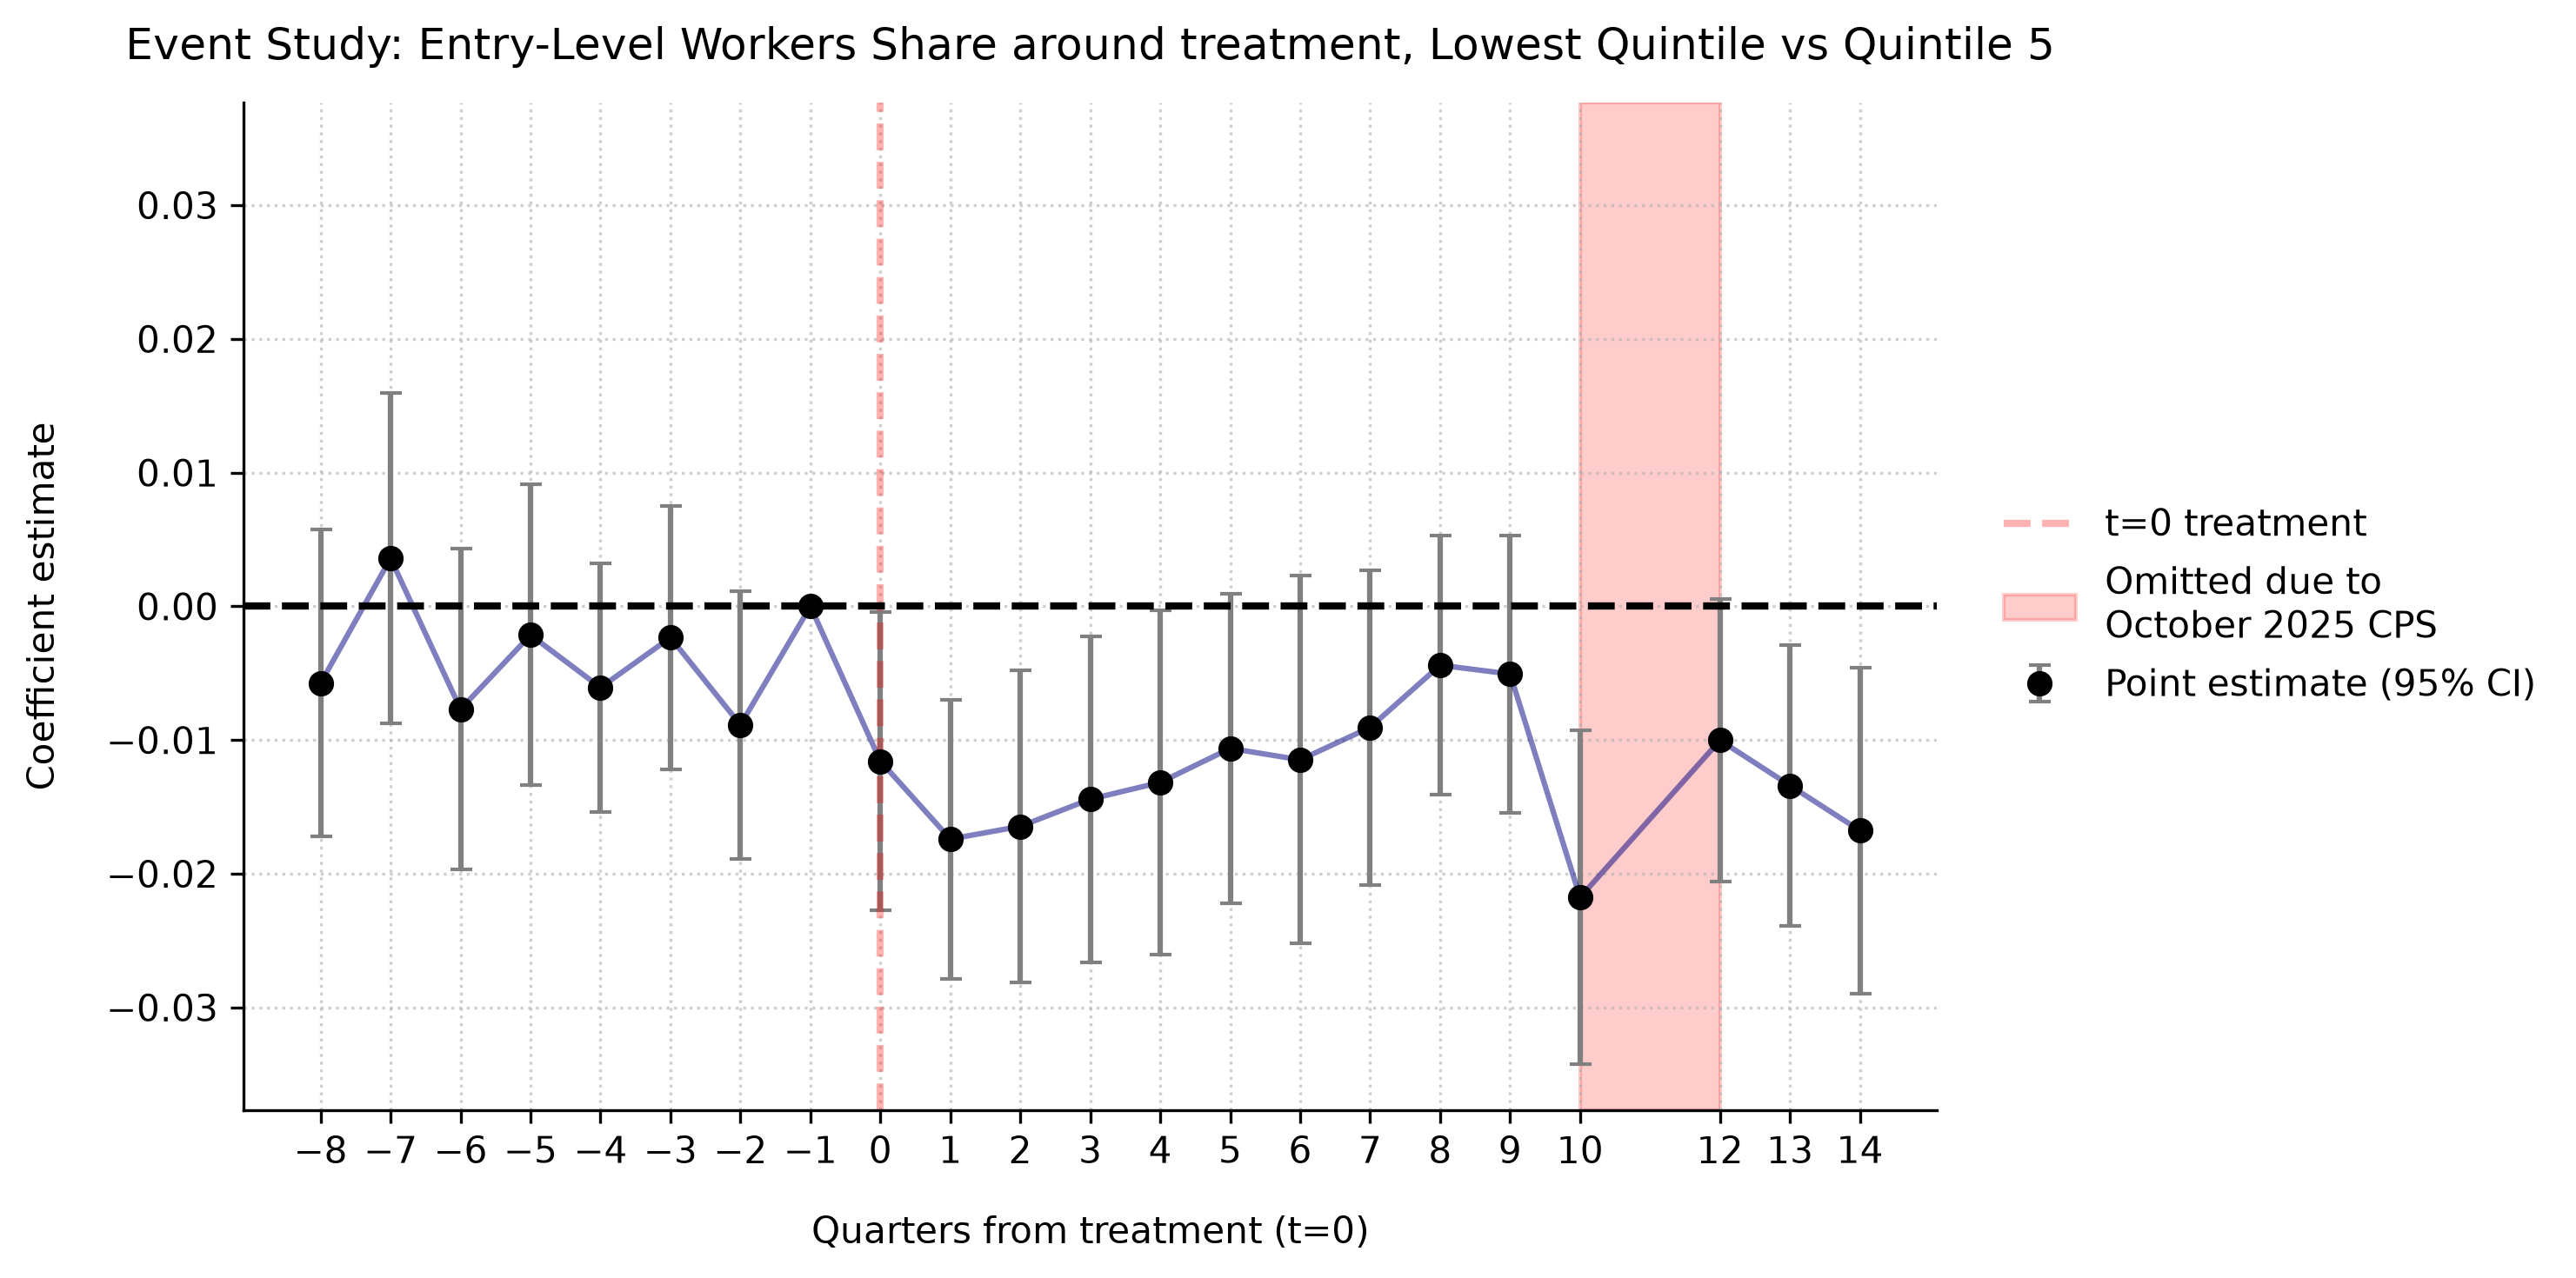

In [44]:
event_study(panel_q_full, 'QUARTER', DV_COL, DV_NAME, 5, 'alpha')

Rows dropped for missing baseline TECH_SHARE: 0
EVENT STUDY FORMULA: Y_SHARE ~ beta_quintile_5:Q("QUARTER_-8") + beta_quintile_5:Q("QUARTER_-7") + beta_quintile_5:Q("QUARTER_-6") + beta_quintile_5:Q("QUARTER_-5") + beta_quintile_5:Q("QUARTER_-4") + beta_quintile_5:Q("QUARTER_-3") + beta_quintile_5:Q("QUARTER_-2") + beta_quintile_5:Q("QUARTER_0") + beta_quintile_5:Q("QUARTER_1") + beta_quintile_5:Q("QUARTER_2") + beta_quintile_5:Q("QUARTER_3") + beta_quintile_5:Q("QUARTER_4") + beta_quintile_5:Q("QUARTER_5") + beta_quintile_5:Q("QUARTER_6") + beta_quintile_5:Q("QUARTER_7") + beta_quintile_5:Q("QUARTER_8") + beta_quintile_5:Q("QUARTER_9") + beta_quintile_5:Q("QUARTER_10") + beta_quintile_5:Q("QUARTER_12") + beta_quintile_5:Q("QUARTER_13") + beta_quintile_5:Q("QUARTER_14") + Q("TECH_BASE_x_QUARTER_-8") + Q("TECH_BASE_x_QUARTER_-7") + Q("TECH_BASE_x_QUARTER_-6") + Q("TECH_BASE_x_QUARTER_-5") + Q("TECH_BASE_x_QUARTER_-4") + Q("TECH_BASE_x_QUARTER_-3") + Q("TECH_BASE_x_QUARTER_-2") + Q("TECH

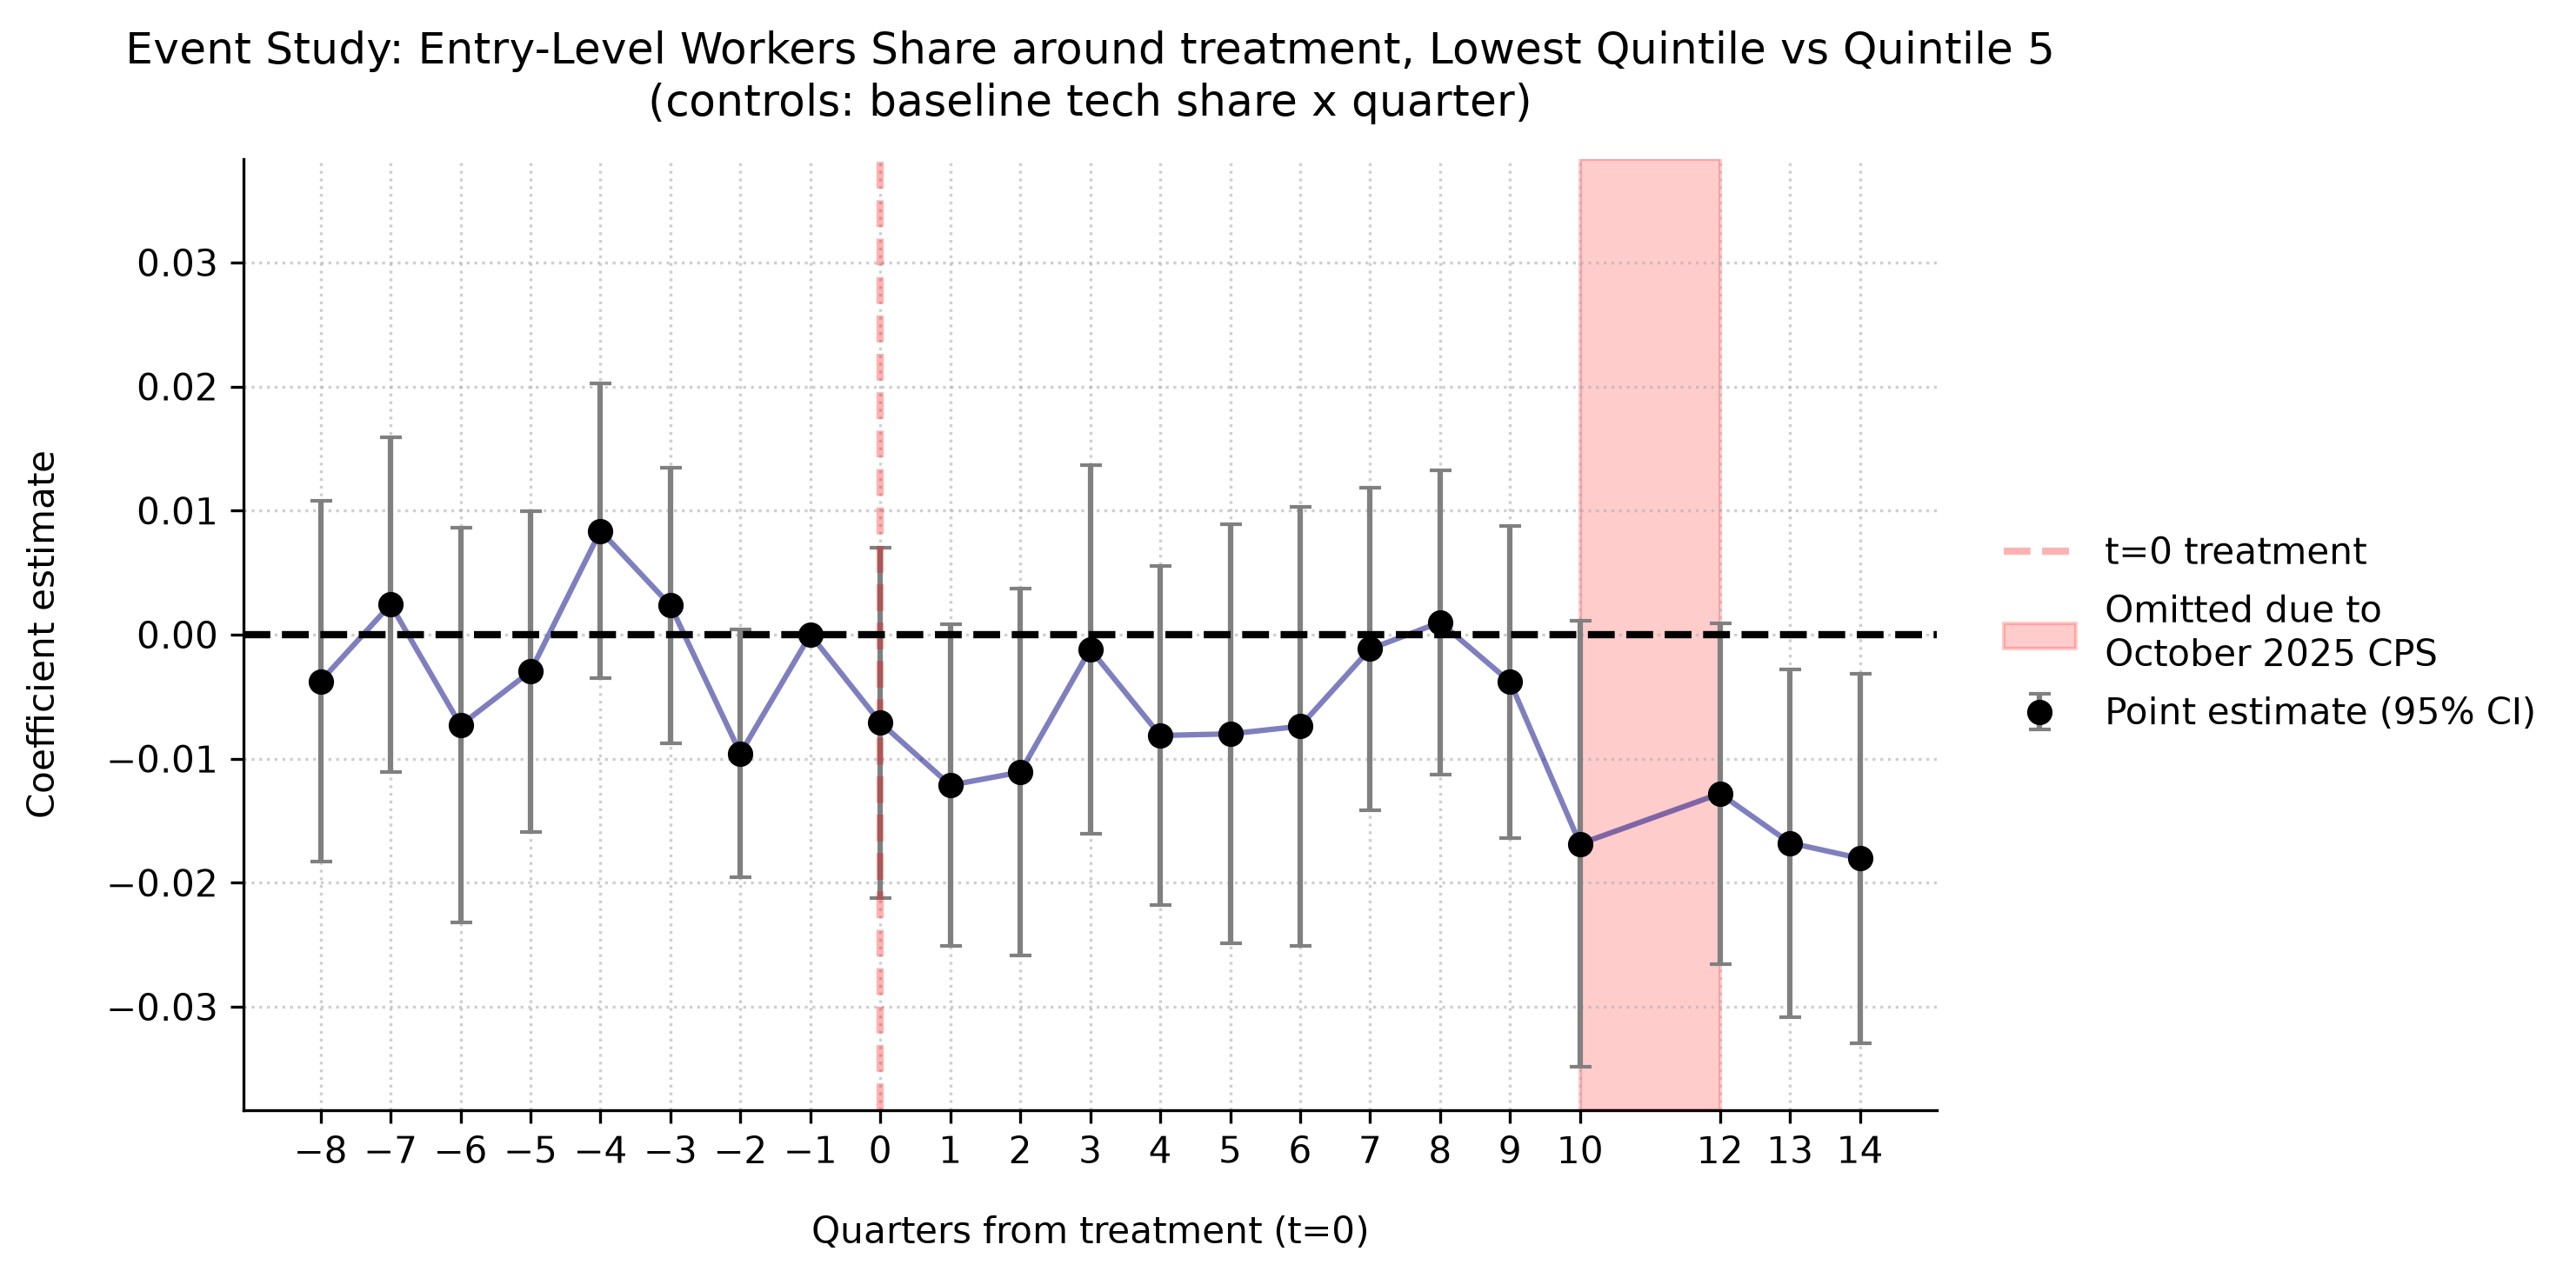

In [30]:
# Event study for just 5th quintile with control for baseline tech share

# --- 1. Baseline TECH_SHARE per OCC (pre-period mean), mapped to every row ---
baseline_tech = (
    panel_q.loc[panel_q['QUARTER'] < 0]
    .groupby('OCC')['TECH_SHARE']
    .mean()                      # for an N-weighted mean, see the note below
    .rename('TECH_BASE')
)
panel_q = panel_q.drop(columns=['TECH_BASE'], errors='ignore')   # safe to re-run
panel_q = panel_q.merge(baseline_tech, left_on='OCC', right_index=True, how='left')

# OCCs with no pre-period observations can't be controlled for
n_missing = panel_q['TECH_BASE'].isna().sum()
print(f"Rows dropped for missing baseline TECH_SHARE: {n_missing}")
panel_q = panel_q.dropna(subset=['TECH_BASE'])

# --- 2. Set up the event-study frame ---
df_event = panel_q.set_index(['OCC', 'QUARTER'], drop=False)

# Filter out unselected quintiles
df_event = df_event[df_event['beta_quintile'].isin([REFERENCE_QUINTILE, 5])]

# Quarter dummies, dropping the reference period (t = -1)
df_event = pd.get_dummies(df_event, columns=['QUARTER'], drop_first=False, dtype=int)
df_event = df_event.drop(columns=['QUARTER_-1'])
quarter_dummies = [c for c in df_event.columns if c.startswith('QUARTER_')]

# --- 3. Baseline control x quarter interactions ---
# The level of TECH_BASE is constant within OCC, so EntityEffects absorbs it.
# Interacting with the quarter dummies lets high- and low-tech OCCs follow different trends.
control_cols = []
for d in quarter_dummies:
    col = f'TECH_BASE_x_{d}'
    df_event[col] = df_event['TECH_BASE'] * df_event[d]
    control_cols.append(col)

# --- 4. Formula ---
interaction_terms = ' + '.join([f'beta_quintile_5:Q("{d}")' for d in quarter_dummies])
control_terms = ' + '.join([f'Q("{c}")' for c in control_cols])
formula = f"{DV_COL} ~ {interaction_terms} + {control_terms} + EntityEffects + TimeEffects"
print(f"EVENT STUDY FORMULA: {formula} {'-'*30}")

# --- 5. Estimate ---
event_study_mod = PanelOLS.from_formula(formula, data=df_event, weights=df_event['N'])
event_study_res = event_study_mod.fit(cov_type='clustered', cluster_entity=True)
print(event_study_res.summary)

# Save output to tex file
# dv_slug = DV_NAME.replace(' ', '_')
# with open(f"{TABLES_PATH}{EVENT_STUDY_FOLDER}{dv_slug}_Quintile{quintile}_reg.tex", "w") as f:
#     f.write(event_study_res.summary.as_latex())

# --- 6. Pull out ONLY the treatment interaction coefficients ---
# (the control terms also contain "QUARTER_k" in their names, so filter first)
df_res = pd.DataFrame({
    'coef': event_study_res.params,
    'lower': event_study_res.conf_int()['lower'],
    'upper': event_study_res.conf_int()['upper']
})
df_res = df_res[df_res.index.str.startswith('beta_quintile_5')].copy()

df_res['quarter'] = (
    df_res.index
    .str.extract(r"QUARTER_(-?\d+)", expand=False)
    .astype(int)
)

# Reinsert the omitted reference period
baseline = pd.DataFrame({'coef': 0.0, 'lower': 0.0, 'upper': 0.0, 'quarter': -1}, index=[-1])
df_res = pd.concat([df_res, baseline]).sort_values('quarter').reset_index(drop=True)

# --- 7. Graph ---
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)

yerr_lower = df_res['coef'] - df_res['lower']
yerr_upper = df_res['upper'] - df_res['coef']

ax.errorbar(
    x=df_res['quarter'],
    y=df_res['coef'],
    yerr=np.asanyarray([yerr_lower, yerr_upper]),
    fmt='o',
    color='black',
    ecolor='gray',
    capsize=3,
    linestyle='None',
    label='Point estimate (95% CI)'
)

ax.plot(df_res['quarter'], df_res['coef'], color='navy', alpha=0.5)

ax.grid(True, linestyle=':', alpha=0.6)

ax.axvline(x=0, color='r', linestyle='--', linewidth=2, alpha=0.3, label="t=0 treatment")
ax.axhline(y=0, color='black', linestyle='--', linewidth=2)
ax.set_xticks(sorted(df_res['quarter'].unique()))

ax.set_xlabel('Quarters from treatment (t=0)', labelpad=12)
ax.set_ylabel('Coefficient estimate', labelpad=12)
ax.set_title(
    f'Event Study: {DV_NAME} around treatment, Lowest Quintile vs Quintile 5\n'
    f'(controls: baseline tech share x quarter)',
    pad=12
)

y_max = max(df_res['upper'].abs().max(), df_res['lower'].abs().max())
margin = y_max * 0.1
ax.set_ylim(-(y_max + margin), y_max + margin)
ax.axvspan(10, 12, color='r', alpha=0.2, label="Omitted due to\nOctober 2025 CPS")

ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='center left', bbox_to_anchor=(1.02, 0.5))

plt.tight_layout()

# fig.savefig(f"{GRAPHS_PATH}{EVENT_STUDY_FOLDER}{dv_slug}_Quintile{quintile}_EventStudy.png", dpi=300, bbox_inches='tight')

In [31]:
### Setup for DiD and placebo tests
placebo_treatments = [-4,-3,-2]
placebo_results = {}

for quintile in quintiles:
    print(quintile)
    # Drop post-treatment and non used quintiles
    df_placebo = panel_q.set_index(['OCC', 'QUARTER'], drop=False)
    df_placebo = df_placebo[(df_placebo['QUARTER'] < 0)]
    df_placebo = df_placebo[df_placebo['beta_quintile'].isin([REFERENCE_QUINTILE, quintile])]

    for treatment_date in placebo_treatments:
        df_placebo['POST'] = (df_placebo['QUARTER'] >= treatment_date).astype(int)
        placebo_formula = f"{DV_COL} ~ POST:beta_quintile_{quintile} + EntityEffects + TimeEffects"
        placebo_mod = PanelOLS.from_formula(placebo_formula, data=df_placebo, weights=df_placebo['N'])
        res_placebo = placebo_mod.fit(cov_type='clustered', cluster_entity=True)
        
        # Key each result by quintile + placebo date so it's identifiable in the table
        placebo_results[f'Q{quintile}, t0={treatment_date}'] = res_placebo

# Build the comparison table
placebo_comparison = compare(placebo_results,  stars=True)
print(placebo_comparison)

# Save to LaTeX for reference
with open(f"{TABLES_PATH}placebo_comparison.tex", "w") as f:
    f.write(placebo_comparison.summary.as_latex())


2
3
4
5
                                                                                         Model Comparison                                                                                        
                             Q2, t0=-4     Q2, t0=-3     Q2, t0=-2     Q3, t0=-4      Q3, t0=-3     Q3, t0=-2     Q4, t0=-4     Q4, t0=-3     Q4, t0=-2     Q5, t0=-4     Q5, t0=-3     Q5, t0=-2
-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Dep. Variable                  Y_SHARE       Y_SHARE       Y_SHARE       Y_SHARE        Y_SHARE       Y_SHARE       Y_SHARE       Y_SHARE       Y_SHARE       Y_SHARE       Y_SHARE       Y_SHARE
Estimator                     PanelOLS      PanelOLS      PanelOLS      PanelOLS       PanelOLS      PanelOLS      PanelOLS      PanelOLS      PanelOLS      PanelOLS      PanelOLS      PanelOLS
No. Observations      

In [32]:
### Linear trend test

for quintile in quintiles:
    df_ltrend = panel_q.set_index(['OCC', 'QUARTER'], drop=False)
    df_ltrend = df_ltrend[df_ltrend['QUARTER'] < 0]
    df_ltrend = df_ltrend[df_ltrend['beta_quintile'].isin([REFERENCE_QUINTILE, quintile])]

    ltrend_formula = f"{DV_COL} ~ QUARTER:beta_quintile_{quintile} + EntityEffects + TimeEffects"
    ltrend_mod = PanelOLS.from_formula(ltrend_formula, data=df_ltrend, weights=df_ltrend['N'])
    res_ltrend = ltrend_mod.fit(cov_type='clustered', cluster_entity=True)
    print(res_ltrend.summary)


                          PanelOLS Estimation Summary                           
Dep. Variable:                Y_SHARE   R-squared:                     1.756e-06
Estimator:                   PanelOLS   R-squared (Between):              0.0005
No. Observations:                 712   R-squared (Within):            8.628e-05
Date:                Wed, Oct 07 2026   R-squared (Overall):              0.0005
Time:                        12:02:17   Log-likelihood                    1628.8
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      0.0011
Entities:                          89   P-value                           0.9738
Avg Obs:                       8.0000   Distribution:                   F(1,615)
Min Obs:                       8.0000                                           
Max Obs:                       8.0000   F-statistic (robust):             0.0004
                            